# Аналіз асортименту та попиту на товари

**Практичне дослідження на основі products.csv, sales.csv та categories.csv.**

Мета роботи - дослідити структуру товарного асортименту, характеристики продажів і відмінності між категоріями, використовуючи Python та бібліотеки Pandas, NumPy, Matplotlib і Seaborn.



In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120

DATA_DIR = Path(".")
products = pd.read_csv(DATA_DIR / "products.csv")
sales = pd.read_csv(DATA_DIR / "sales.csv")
categories = pd.read_csv(DATA_DIR / "categories.csv")

print("products ", products.shape)
print("sales ", sales.shape)
print("categories ", categories.shape)


products  (1200, 6)
sales  (5000, 7)
categories  (1000, 3)


## 1. Огляд вихідних таблиць

На першому етапі розглядаємо структуру файлів, назви колонок, типи даних і кілька рядків. Це дає змогу зрозуміти, які атрибути описують товари, продажі та категорії.

In [25]:
display(products.head())
display(sales.head())
display(categories.head())

print("\n\nКолонки products ", products.columns.tolist())
print("Колонки sales ", sales.columns.tolist())
print("Колонки categories ", categories.columns.tolist())


,product_id,product_name,category_id,brand,purchase_price,retail_price
0,101,Ugreen Чохли протиударні Mod-101,436,Ugreen,310,869
1,102,Hoco Захисне скло 3D/5D Mod-102,615,Hoco,161,309
2,103,Sony Чохли протиударні Mod-103,459,Sony,127,279
3,104,Realme Гідрогелеві плівки Mod-104,664,Realme,170,289
4,105,Samsung Портативна акустика Mod-105,344,Samsung,7749,9299


,transaction_id,order_id,date,product_id,quantity,discount_pct,payment_type
0,1,12573,2026-05-14 20:15:14,260,1,0.0,Картка
1,2,11479,2026-07-02 13:22:28,849,1,0.0,Готівка
2,3,11845,2026-08-13 13:08:52,426,1,0.0,Картка
3,4,12540,2026-06-26 18:42:42,693,1,0.0,Картка
4,5,10074,2026-09-12 12:03:04,192,2,0.0,Картка


,category_id,category_name,group
0,1,Смартфони (Економ - Рівень 1),Основна техніка
1,2,Смартфони (Економ - Рівень 2),Основна техніка
2,3,Смартфони (Економ - Рівень 3),Основна техніка
3,4,Смартфони (Економ - Рівень 4),Основна техніка
4,5,Смартфони (Стандарт - Рівень 1),Основна техніка




Колонки products  ['product_id', 'product_name', 'category_id', 'brand', 'purchase_price', 'retail_price']
Колонки sales  ['transaction_id', 'order_id', 'date', 'product_id', 'quantity', 'discount_pct', 'payment_type']
Колонки categories  ['category_id', 'category_name', 'group']


In [26]:
for name, table in [("products", products), ("sales", sales), ("categories", categories)]:
    print(f"\n\n--- {name} ---")
    table.info()




--- products ---
<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   product_id      1200 non-null   int64
 1   product_name    1200 non-null   str  
 2   category_id     1200 non-null   int64
 3   brand           1200 non-null   str  
 4   purchase_price  1200 non-null   int64
 5   retail_price    1200 non-null   int64
dtypes: int64(4), str(2)
memory usage: 56.4 KB


--- sales ---
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   transaction_id  5000 non-null   int64  
 1   order_id        5000 non-null   int64  
 2   date            5000 non-null   str    
 3   product_id      5000 non-null   int64  
 4   quantity        5000 non-null   int64  
 5   discount_pct    5000 non-null   float64
 6   payment_type    495

## 2. Перевірка якості даних

Перевіряємо пропущені значення, повтори та основні статистичні характеристики. Під час очищення не будемо автоматично видаляти всі пропуски: рішення залежатиме від того, в якій колонці вони виникають.

In [27]:
for name, table in [("products", products), ("sales", sales), ("categories", categories)]:
    print(f"\n\n{name} ")
    display(table.isna().sum().to_frame("missing_values"))
    print("Повністю повторюваних рядків ", table.duplicated().sum())
    display(table.describe(include="all").transpose())




products 


,missing_values
product_id,0
product_name,0
category_id,0
brand,0
purchase_price,0
retail_price,0


Повністю повторюваних рядків  0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
product_id,1200.0,NaN,NaN,NaN,700.5,346.554469,101.0,400.75,700.5,1000.25,1300.0
product_name,1200,1200,Ugreen Чохли протиударні Mod-101,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category_id,1200.0,NaN,NaN,NaN,511.6,288.468251,1.0,258.75,519.0,767.25,999.0
brand,1200,11,Apple,131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
purchase_price,1200.0,NaN,NaN,NaN,4597.649167,8466.612464,40.0,363.0,679.0,5185.25,39629.0
retail_price,1200.0,NaN,NaN,NaN,5941.375,9801.281602,79.0,869.0,1599.0,6971.5,48609.0




sales 


,missing_values
transaction_id,0
order_id,0
date,0
product_id,0
quantity,0
discount_pct,0
payment_type,45


... (2 outputs left out)



categories 


,missing_values
category_id,0
category_name,0
group,0


Повністю повторюваних рядків  0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
category_id,1000.0,NaN,NaN,NaN,500.5,288.819436,1.0,250.75,500.5,750.25,1000.0
category_name,1000,1000,Смартфони (Економ - Рівень 1),1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
group,1000,5,Аксесуари,576,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Підготовка та очищення таблиць

Спершу видаляємо повністю дубльовані рядки. Далі виводимо основні поля, щоб за результатами первинного огляду визначити ключі для об'єднання таблиць.

In [28]:
products_clean = products.drop_duplicates().copy()
sales_clean = sales.drop_duplicates().copy()
categories_clean = categories.drop_duplicates().copy()

print("Розміри після видалення повних дублікатів ")
print(products_clean.shape, sales_clean.shape, categories_clean.shape)


Розміри після видалення повних дублікатів 
(1200, 6) (5000, 7) (1000, 3)


### 3.1. Визначення полів та об'єднання таблиць

Наведений блок намагається визначити типові назви колонок за їхніми заголовками. Якщо назви у файлах відрізняються, після перегляду виведених списків можна скоригувати поля вручну.

In [30]:
def find_col(df, candidates):
    normalized = {str(c).lower().strip().replace(" ", "_"): c for c in df.columns}
    for cand in candidates:
        key = cand.lower().strip().replace(" ", "_")
        if key in normalized:
            return normalized[key]
   
    for key, original in normalized.items():
        if any(cand.lower().replace(" ", "_") in key for cand in candidates):
            return original
    return None

product_key = find_col(products_clean, ["product_id", "id_product", "productid", "id", "sku"])
sales_product_key = find_col(sales_clean, ["product_id", "id_product", "productid", "sku"])
category_key_products = find_col(products_clean, ["category_id", "id_category", "categoryid"])
category_key_categories = find_col(categories_clean, ["category_id", "id_category", "categoryid", "id"])

print("Ключ товару ", product_key)
print("Ключ товару в продажах ", sales_product_key)
print("Ключ категорії в товарах ", category_key_products)
print("Ключ категорії в довіднику ", category_key_categories)

print("products ", products_clean.columns.tolist())
print("sales ", sales_clean.columns.tolist())
print("categories ", categories_clean.columns.tolist())


Ключ товару  product_id
Ключ товару в продажах  product_id
Ключ категорії в товарах  category_id
Ключ категорії в довіднику  category_id
products  ['product_id', 'product_name', 'category_id', 'brand', 'purchase_price', 'retail_price']
sales  ['transaction_id', 'order_id', 'date', 'product_id', 'quantity', 'discount_pct', 'payment_type']
categories  ['category_id', 'category_name', 'group']


In [31]:
if product_key is not None and sales_product_key is not None:
    df = sales_clean.merge(
        products_clean,
        left_on=sales_product_key,
        right_on=product_key,
        how="left",
        suffixes=("_sale", "_product")
    )
else:
    raise ValueError("Не вдалося автоматично знайти ключ товару. Перевірте назви колонок та задайте ключі вручну.")

if category_key_products and category_key_categories:
    cat_map = categories_clean.copy()
    df = df.merge(
        cat_map,
        left_on=category_key_products,
        right_on=category_key_categories,
        how="left",
        suffixes=("", "_category")
    )

print("Розмір об'єднаної таблиці ", df.shape)
display(df.head())


Розмір об'єднаної таблиці  (5000, 14)


,transaction_id,order_id,date,product_id,quantity,discount_pct,payment_type,product_name,category_id,brand,purchase_price,retail_price,category_name,group
0,1,12573,2026-05-14 20:15:14,260,1,0.0,Картка,Realme Павербанки 20000mAh+ Mod-260,929,Realme,156,489,Павербанки 20000mAh+ (Ultra серія - Рівень 1),Аксесуари
1,2,11479,2026-07-02 13:22:28,849,1,0.0,Готівка,Apple Чохли силіконові Mod-849,432,Apple,709,1659,Чохли силіконові (Color Line - Рівень 4),Аксесуари
2,3,11845,2026-08-13 13:08:52,426,1,0.0,Картка,Baseus Ноутбуки Mod-426,113,Baseus,30762,35209,Ноутбуки (Ultra серія - Рівень 1),Основна техніка
3,4,12540,2026-06-26 18:42:42,693,1,0.0,Картка,JBL Чохли силіконові Mod-693,397,JBL,664,2079,Чохли силіконові (Pro версія - Рівень 1),Аксесуари
4,5,10074,2026-09-12 12:03:04,192,2,0.0,Картка,Motorola Кабелі Lightning Mod-192,811,Motorola,285,639,Кабелі Lightning (Compact - Рівень 3),Аксесуари


## 4. Конструювання аналітичних показників

Для подальшого аналізу необхідно визначити числові поля продажів: кількість реалізованих одиниць і ціну. Автоматичний пошук використовує поширені варіанти назв колонок. Якщо назви не знайдено, користувач може задати їх вручну.

In [32]:
quantity_col = find_col(df, ["quantity", "qty", "units_sold", "count", "amount"])
price_col = find_col(df, ["price", "unit_price", "selling_price", "sale_price"])
date_col = find_col(df, ["date", "sale_date", "order_date", "datetime", "timestamp"])
product_name_col = find_col(df, ["product_name", "name", "title", "product"])
category_name_col = find_col(df, ["category_name", "category", "name_category"])

print("Кількість ", quantity_col)
print("Ціна ", price_col)
print("Дата ", date_col)
print("Назва товару ", product_name_col)
print("Категорія ", category_name_col)



Кількість  quantity
Ціна  purchase_price
Дата  date
Назва товару  product_name
Категорія  category_name


In [33]:
if quantity_col is not None and price_col is not None:
    df[quantity_col] = pd.to_numeric(df[quantity_col], errors="coerce")
    df[price_col] = pd.to_numeric(df[price_col], errors="coerce")
    df["revenue"] = df[quantity_col] * df[price_col]
else:
    print("Не знайдено колонку кількості або ціни - задайте їх вручну, щоб розрахувати виручку.")

if date_col is not None:
    df[date_col] = pd.to_datetime(df[date_col], errors="coerce")

display(df.head())


,transaction_id,order_id,date,product_id,quantity,discount_pct,payment_type,product_name,category_id,brand,purchase_price,retail_price,category_name,group,revenue
0,1,12573,2026-05-14 20:15:14,260,1,0.0,Картка,Realme Павербанки 20000mAh+ Mod-260,929,Realme,156,489,Павербанки 20000mAh+ (Ultra серія - Рівень 1),Аксесуари,156
1,2,11479,2026-07-02 13:22:28,849,1,0.0,Готівка,Apple Чохли силіконові Mod-849,432,Apple,709,1659,Чохли силіконові (Color Line - Рівень 4),Аксесуари,709
2,3,11845,2026-08-13 13:08:52,426,1,0.0,Картка,Baseus Ноутбуки Mod-426,113,Baseus,30762,35209,Ноутбуки (Ultra серія - Рівень 1),Основна техніка,30762
3,4,12540,2026-06-26 18:42:42,693,1,0.0,Картка,JBL Чохли силіконові Mod-693,397,JBL,664,2079,Чохли силіконові (Pro версія - Рівень 1),Аксесуари,664
4,5,10074,2026-09-12 12:03:04,192,2,0.0,Картка,Motorola Кабелі Lightning Mod-192,811,Motorola,285,639,Кабелі Lightning (Compact - Рівень 3),Аксесуари,570


## 5. Загальна характеристика продажів

Після об'єднання таблиць оцінюємо числові показники, структуру асортименту та основні підсумки. Результати розрахунків слугують базою для порівняльного аналізу.

In [34]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
display(df[numeric_columns].describe().round(2))

if "revenue" in df.columns:
    print("Загальна виручка ", round(df["revenue"].sum(), 2))
    print("Середня виручка запису ", round(df["revenue"].mean(), 2))
    print("Медіана виручки запису ", round(df["revenue"].median(), 2))


,transaction_id,order_id,product_id,quantity,discount_pct,category_id,purchase_price,retail_price,revenue
count,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00
mean,2500.50,11767.17,688.71,1.26,0.02,646.65,1240.09,2042.16,1597.47
std,1443.52,1015.12,345.31,0.63,0.04,222.64,3429.45,4036.99,5414.48
min,1.00,10001.00,101.00,1.00,0.00,2.00,40.00,79.00,40.00
25%,1250.75,10876.75,387.00,1.00,0.00,482.00,266.00,629.00,300.00
50%,2500.50,11800.00,690.00,1.00,0.00,664.00,488.00,1179.00,533.00
75%,3750.25,12642.50,985.00,1.00,0.05,828.00,727.00,1739.00,834.00
max,5000.00,13499.00,1299.00,4.00,0.15,999.00,39629.00,46229.00,156696.00


Загальна виручка  7987328
Середня виручка запису  1597.47
Медіана виручки запису  533.0


### 5.1. Рейтинг товарів за обсягом продажів

Сортування дає змогу визначити товари, які формують найбільший обсяг реалізації. Результат залежить від наявності поля кількості у вихідних даних.

In [35]:
if quantity_col is not None:
    if product_name_col is not None:
        product_sales = df.groupby(product_name_col, dropna=False)[quantity_col].sum().sort_values(ascending=False)
    else:
        product_sales = df.groupby(sales_product_key, dropna=False)[quantity_col].sum().sort_values(ascending=False)
    display(product_sales.head(15).to_frame("units_sold"))
else:
    print("Для рейтингу за обсягом продажів потрібне поле кількості.")


,units_sold
product_name,
Hoco Павербанки до 10000mAh Mod-1082,24
Motorola Гідрогелеві плівки Mod-144,22
Apple Захисне скло 3D/5D Mod-277,19
Ugreen Павербанки 20000mAh+ Mod-402,18
Sony Кабелі Lightning Mod-1013,18
Ugreen Чохли протиударні Mod-101,18
Xiaomi Чохли силіконові Mod-751,18
Hoco Автомобільні тримачі Mod-650,17
Ugreen Захисне скло 2.5D Mod-988,17


### 5.2. Групування за категоріями

Групові підсумки дозволяють порівнювати категорії за обсягом продажів та, якщо розраховано, за виручкою.

In [12]:
if category_name_col is not None:
    metrics = {}
    if quantity_col is not None:
        metrics["units_sold"] = (quantity_col, "sum")
    if "revenue" in df.columns:
        metrics["revenue"] = ("revenue", "sum")
    if metrics:
        category_summary = df.groupby(category_name_col, dropna=False).agg(**metrics).sort_values(
            list(metrics.keys())[0], ascending=False
        )
        display(category_summary)
    else:
        print("Не знайдено показників для агрегування.")
else:
    print("Назву категорії не визначено автоматично. Перевірте таблицю categories.")


,units_sold,revenue
category_name,,
Бездротові зарядки (Преміум - Рівень 1),57,9425
Кабелі Type-C (Gaming Edition - Рівень 2),45,18281
Гідрогелеві плівки (Color Line - Рівень 2),44,21477
Павербанки 20000mAh+ (Slim - Рівень 4),43,19328
Кабелі Type-C (Стандарт - Рівень 1),42,18436
...,...,...
Ноутбуки (Compact - Рівень 1),1,38409
Фітнес-браслети (Стандарт - Рівень 2),1,2083
Захисне скло 3D/5D (Gaming Edition - Рівень 1),1,727


### 5.3. Таблиця зведення

Зведена таблиця може показати агрегований показник за категоріями. Якщо категоріальне поле або показник недоступні, цей блок пропускається.

In [36]:
if category_name_col is not None and quantity_col is not None:
    pivot = pd.pivot_table(
        df,
        index=category_name_col,
        values=quantity_col,
        aggfunc="sum",
        fill_value=0
    ).sort_values(quantity_col, ascending=False)
    display(pivot)
else:
    print("Для зведеної таблиці потрібні категорія та кількість.")


,quantity
category_name,
Бездротові зарядки (Преміум - Рівень 1),57
Кабелі Type-C (Gaming Edition - Рівень 2),45
Гідрогелеві плівки (Color Line - Рівень 2),44
Павербанки 20000mAh+ (Slim - Рівень 4),43
Кабелі Type-C (Стандарт - Рівень 1),42
...,...
Ноутбуки (Compact - Рівень 1),1
Фітнес-браслети (Стандарт - Рівень 2),1
Захисне скло 3D/5D (Gaming Edition - Рівень 1),1


## 6 Візуальний аналіз

Нижче наведено графіки, що відображають різні аспекти даних.

### 6.1. Топ товарів за кількістю продажів

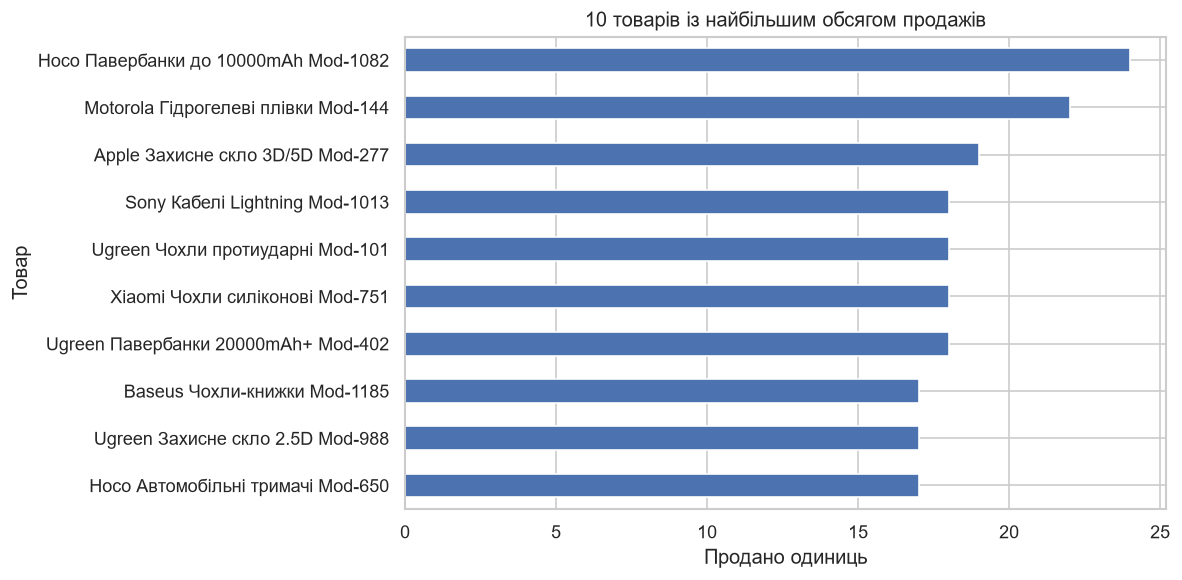

In [37]:
if quantity_col is not None:
    if product_name_col is not None:
        top_products = df.groupby(product_name_col)[quantity_col].sum().sort_values(ascending=False).head(10)
    else:
        top_products = df.groupby(sales_product_key)[quantity_col].sum().sort_values(ascending=False).head(10)
    plt.figure(figsize=(10, 5))
    top_products.sort_values().plot(kind="barh")
    plt.title("10 товарів із найбільшим обсягом продажів")
    plt.xlabel("Продано одиниць")
    plt.ylabel("Товар")
    plt.tight_layout()
    plt.show()


### 6.2. Виручка за категоріями

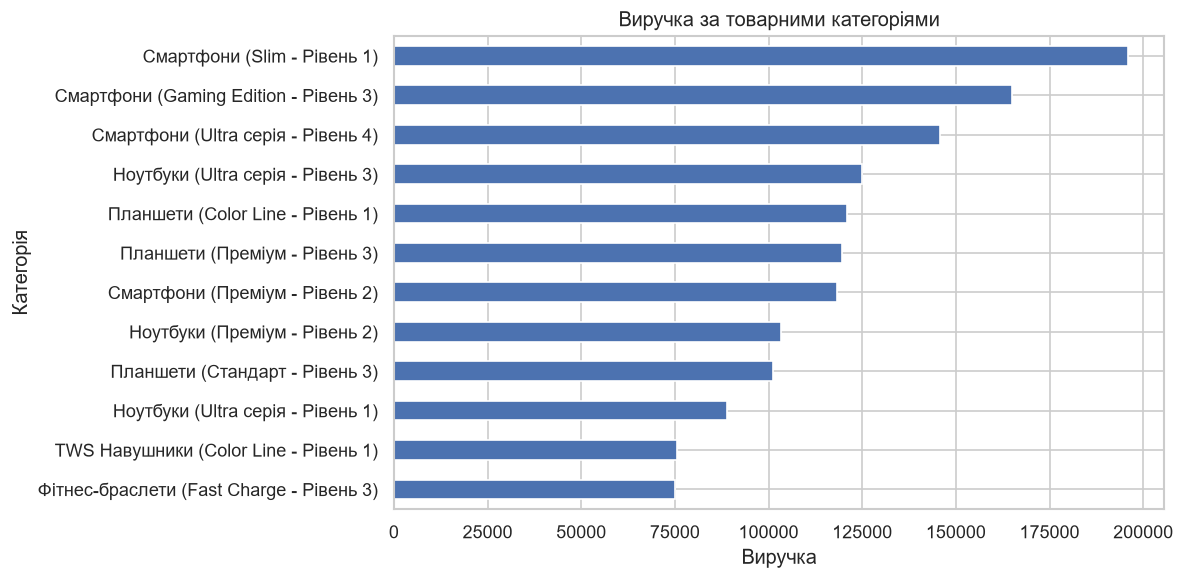

In [38]:
if category_name_col is not None and "revenue" in df.columns:
    cat_rev = df.groupby(category_name_col)["revenue"].sum().sort_values(ascending=False).head(12)
    plt.figure(figsize=(10, 5))
    cat_rev.sort_values().plot(kind="barh")
    plt.title("Виручка за товарними категоріями")
    plt.xlabel("Виручка")
    plt.ylabel("Категорія")
    plt.tight_layout()
    plt.show()


### 6.3. Розподіл кількості реалізованих одиниць

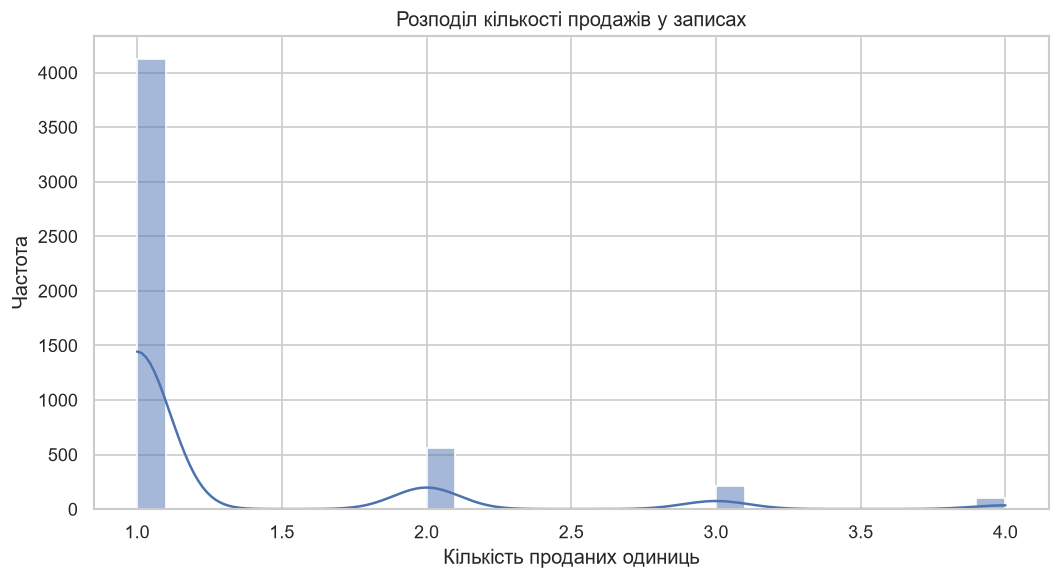

In [39]:
if quantity_col is not None:
    plt.figure(figsize=(9, 5))
    sns.histplot(data=df, x=quantity_col, bins=30, kde=True)
    plt.title("Розподіл кількості продажів у записах")
    plt.xlabel("Кількість проданих одиниць")
    plt.ylabel("Частота")
    plt.tight_layout()
    plt.show()


### 6.4. Ціна та обсяг продажів

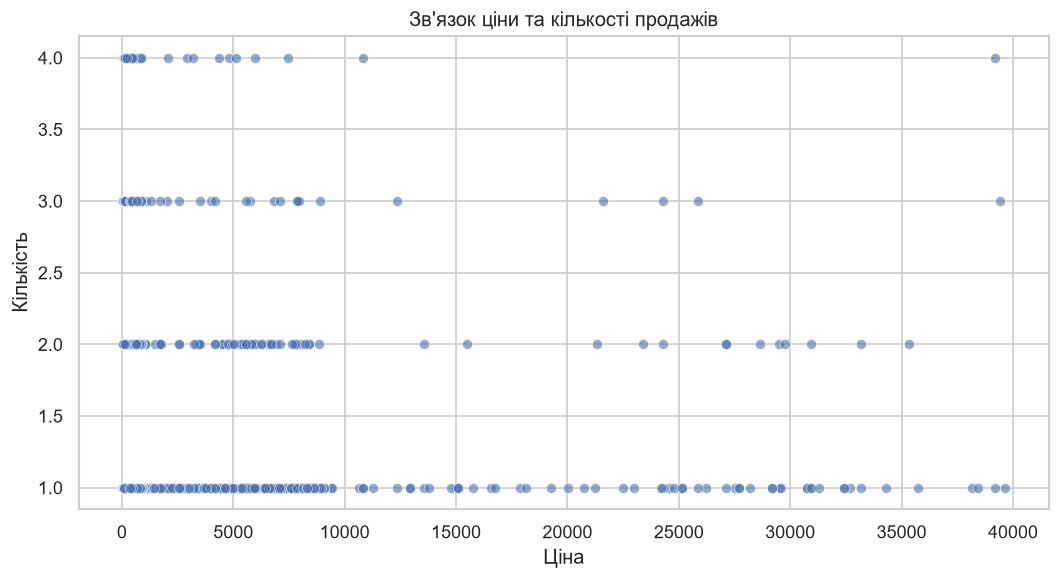

In [40]:
if quantity_col is not None and price_col is not None:
    scatter_df = df[[quantity_col, price_col]].dropna()
    plt.figure(figsize=(9, 5))
    sns.scatterplot(data=scatter_df, x=price_col, y=quantity_col, alpha=0.6)
    plt.title("Зв'язок ціни та кількості продажів")
    plt.xlabel("Ціна")
    plt.ylabel("Кількість")
    plt.tight_layout()
    plt.show()


### 6.5. Динаміка продажів у часі


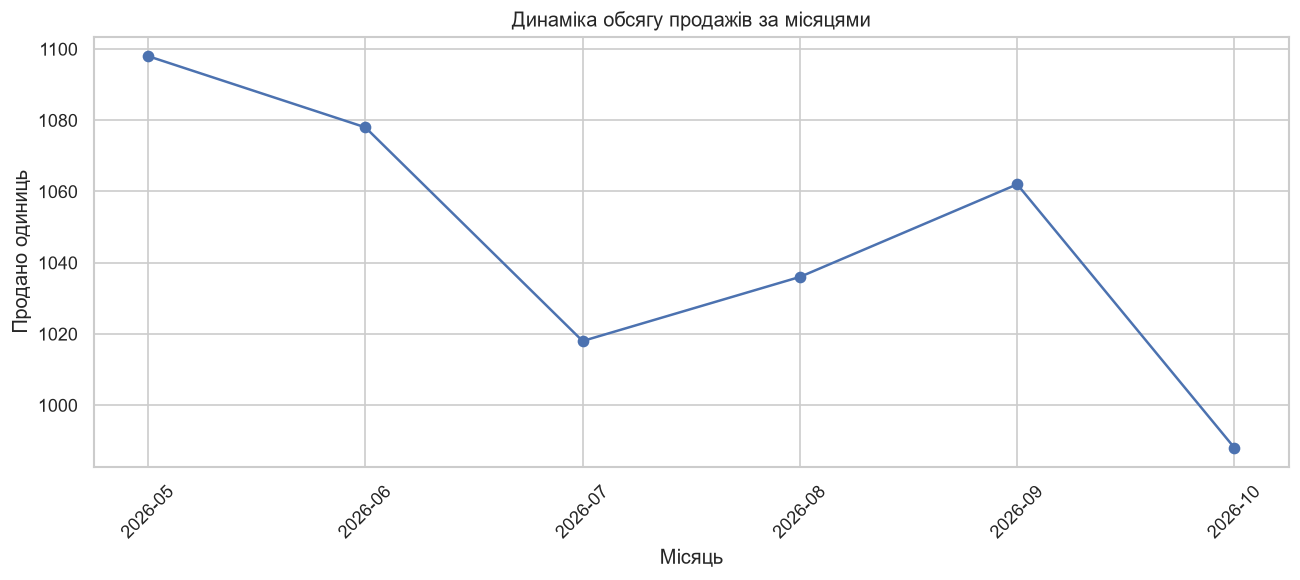

In [ ]:
if date_col is not None and quantity_col is not None:
    time_df = df.dropna(subset=[date_col]).copy()
    time_df["month"] = time_df[date_col].dt.to_period("M").astype(str)
    monthly = time_df.groupby("month")[quantity_col].sum()
    plt.figure(figsize=(11, 5))
    monthly.plot(marker="o")
    plt.title("Динаміка обсягу продажів за місяцями")
    plt.xlabel("Місяць")
    plt.ylabel("Продано одиниць")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("Динамічний графік не побудовано у даних не виявлено дату та/або кількість.")


### 6.6. Кореляційний аналіз числових показників

Кореляція дає змогу оцінити статистичну взаємодію числових змінних. Вона не є доказом причинно-наслідкового зв'язку.

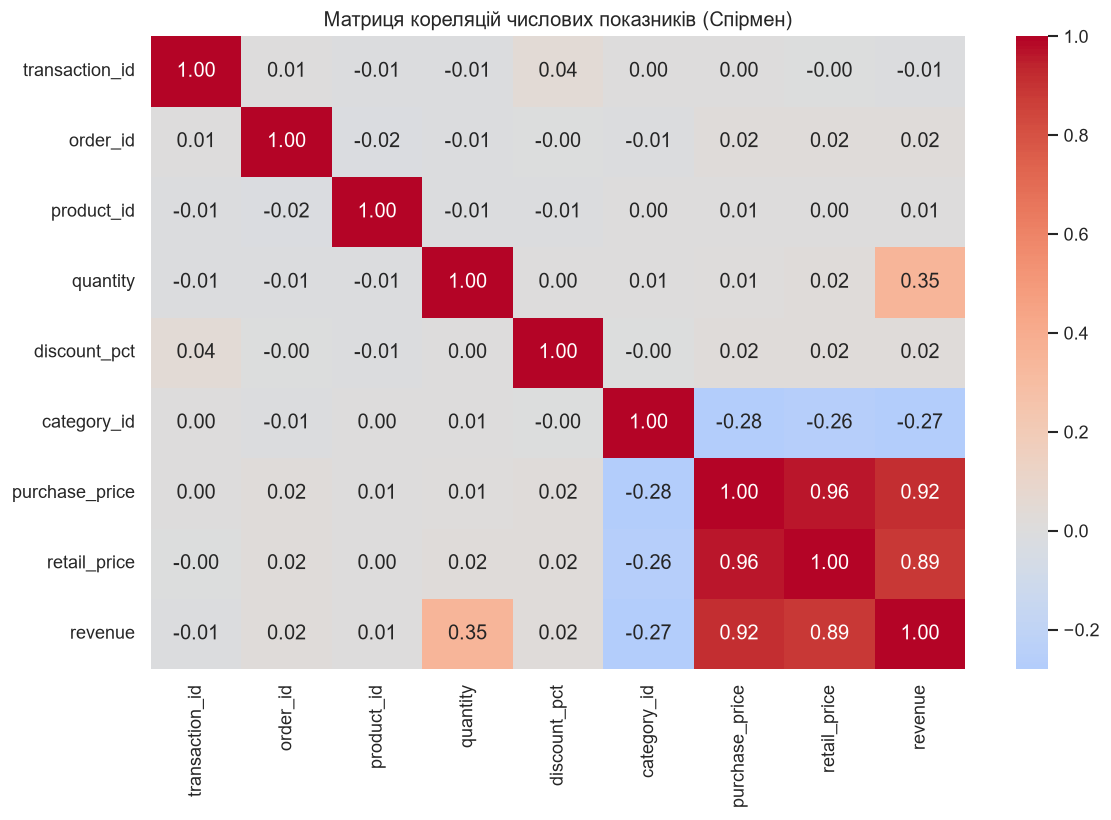

In [43]:
corr_data = df.select_dtypes(include=np.number)
if corr_data.shape[1] >= 2:
    corr = corr_data.corr(method="spearman")
    plt.figure(figsize=(10, 7))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Матриця кореляцій числових показників (Спірмен)")
    plt.tight_layout()
    plt.show()
else:
    print("Недостатньо числових колонок для кореляційної матриці.")


## 7. Експорт результатів

Збережемо об'єднану таблицю для повторного використання результатів аналізу або подальшого завантаження у Tableau.

In [ ]:
df["revenue"] = (
    df["quantity"] *
    df["retail_price"] *
    (1 - df["discount_pct"])
)
df.to_csv("analysis_dataset.csv", index=False, encoding="utf-8-sig")
print("Файл analysis_dataset.csv збережено.")


Файл analysis_dataset.csv збережено.


## 8. Підсумки дослідження

## Висновки до практичної частини

У ході практичного дослідження було проведено аналіз асортименту та попиту на товари на основі трьох наборів даних: інформації про товари, операції продажів та довідника товарних категорій. Для виконання дослідження використовувалися бібліотеки Python Pandas, NumPy, Matplotlib та Seaborn, які дали змогу здійснити обробку, аналіз та візуалізацію даних.

На початковому етапі було проаналізовано структуру вихідних таблиць. Таблиця товарів містить 1200 записів, таблиця продажів - 5000 записів, а довідник категорій - 1000 записів. У процесі первинної перевірки було встановлено, що таблиці товарів і категорій не містять пропущених значень. У таблиці продажів було виявлено 45 пропущених значень у полі способу оплати. Також у вихідних таблицях не було виявлено повністю дубльованих рядків.

Для подальшого аналізу таблиці було об'єднано за відповідними ідентифікаторами товарів та категорій. Це дозволило сформувати таблицю, що містить інформацію про операції продажів, характеристики товарів, їхні бренди, ціни та категорії. Об'єднаний набір даних містить 5000 записів і 14 колонок, що створює основу для комплексного дослідження товарного асортименту.

Аналіз кількісних показників продажів показав, що середня кількість товарів у записі становить 1256 одиниці, тоді як медіанне значення дорівнює 1. Це свідчить про те, що більшість записів продажів характеризується реалізацією однієї одиниці товару, хоча в окремих випадках покупці придбавали більшу кількість товарів за одну операцію. Максимальна кількість товарів у записі становила 4 одиниці.

У результаті ранжування товарів за кількістю реалізованих одиниць було визначено позиції з найбільшим обсягом продажів. Серед лідерів виявилися портативні зарядні пристрої, захисні аксесуари для мобільних пристроїв, кабелі та інші супутні товари. Зокрема, найбільший результат у сформованому рейтингу продемонстрував товар Hoco «Павербанки до 10000mAh Mod-1082», кількість продажів якого становила 24 одиниці. Це демонструє доцільність використання рейтингового аналізу для визначення популярних товарних позицій.

Групування даних за товарними категоріями дозволило порівняти обсяги реалізації різних позицій асортименту. Серед категорій з найбільшими показниками кількості продажів у сформованій таблиці були бездротові зарядки, кабелі Type-C, гідрогелеві плівки та павербанки. Такий аналіз дає змогу виділити товарні категорії, які можуть бути перспективними для подальшого дослідження попиту та планування асортименту.

За допомогою зведеної таблиці було систематизовано обсяг реалізації за товарними категоріями. Використання групування та агрегування даних дозволило скоротити обсяг інформації до узагальнених показників, що спрощує порівняння товарних позицій і пошук закономірностей у структурі продажів.

Для візуального дослідження даних було сформовано графіки рейтингу товарів, виручки за категоріями, розподілу кількості продажів, взаємозв'язку ціни та кількості реалізованих одиниць, динаміки продажів у часі та кореляційної матриці числових показників. Візуалізація дозволяє представити результати аналізу у зрозумілій формі та сприяє виявленню особливостей структури продажів.

Таким чином, проведене дослідження продемонструвало можливості використання Python та бібліотек для аналізу даних у задачах дослідження товарного асортименту та попиту. Застосування методів очищення, об'єднання, групування, ранжування, зведених таблиць і візуалізації дозволило сформувати інформаційну основу для оцінювання популярності товарів та порівняння категорій. Отримані результати можуть використовуватися як основа для подальшого аналізу асортиментної політики та прийняття рішень щодо управління товарними запасами.
